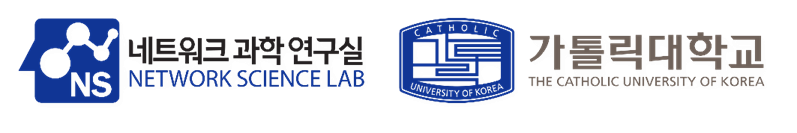


# Solution 4: Scalability of GNNs


### Assignment 1. Given the Citeseer graph:
Questions:

1) Show some graph statistics of the Citeseer graph (Number of nodes, Number of edges, ...)
2) Running the GraphSAGE, FastGCN, ASGCN, GraphSAINT, and ClusterGCN models on node classification on the Citeseer graph. 

In [1]:
DATASET_NAME = "Citeseer"

import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.utils import add_self_loops, degree, subgraph

SEED = 42
EPOCHS = 40
HIDDEN = 64
DROPOUT = 0.5
LEARNING_RATE = 0.01
WEIGHT_DECAY = 5e-4
BATCH_SIZE = 128

# GraphSAGE: neighbors kept at hop 1, then at hop 2.
FANOUTS = [10, 10]
# FastGCN: one shared sample. The paper uses 400 nodes on Cora.
FASTGCN_SAMPLES = 400
# ASGCN: nodes drawn for the input layer, then the hidden layer.
LAYER_SAMPLES = [128, 64]
# GraphSAINT random walks.
WALK_LENGTH = 2
SAINT_STEPS = 5
SAMPLE_COVERAGE = 20
# ClusterGCN: partition once, then glue a few clusters into each batch.
NUM_CLUSTERS = 8
CLUSTERS_PER_BATCH = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything()
print(f"PyTorch {torch.__version__} | device {DEVICE}")


PyTorch 2.8.0+cpu | device cpu


In [2]:
dataset = Planetoid(root="data", name=DATASET_NAME, split="public", transform=NormalizeFeatures())
data = dataset[0]
data.y = data.y.view(-1)

print(f"Dataset: {DATASET_NAME}")
print(f"Number of nodes: {data.num_nodes}")
print(f"Number of edges: {data.num_edges}")
print(f"Node feature length: {dataset.num_node_features}")
print(f"Number of classes: {dataset.num_classes}")
print(
    "Train / val / test nodes: "
    f"{int(data.train_mask.sum())} / {int(data.val_mask.sum())} / {int(data.test_mask.sum())}"
)


Dataset: Citeseer
Number of nodes: 3327
Number of edges: 9104
Node feature length: 3703
Number of classes: 6
Train / val / test nodes: 120 / 500 / 1000


In [3]:
results = {}


def accuracies(pred):
    scores = {}
    for split, mask in (("train", data.train_mask), ("val", data.val_mask), ("test", data.test_mask)):
        correct = pred[mask] == data.y[mask]
        scores[split] = correct.float().mean().item()
    return scores


def plot_history(history, name):
    epochs = [row[0] for row in history]
    losses = [row[1] for row in history]
    val_scores = [row[2] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    axes[0].plot(epochs, losses, color="#2563eb")
    axes[0].set(title=f"{name} training loss", xlabel="Epoch", ylabel="Loss")
    axes[1].plot(epochs, val_scores, color="#d97706")
    axes[1].set(title=f"{name} validation accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
    for ax in axes:
        ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()


def fit(name, model, train_epoch, predict):
    """Train, keep the best validation epoch, and score that checkpoint on the test nodes."""
    best_val = -1.0
    best_epoch = 0
    best_state = None
    history = []
    for epoch in range(1, EPOCHS + 1):
        loss = train_epoch()
        scores = accuracies(predict())
        history.append((epoch, loss, scores["val"]))
        if scores["val"] > best_val:
            best_val = scores["val"]
            best_epoch = epoch
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        if epoch == 1 or epoch % 10 == 0:
            print(f"Epoch {epoch:02d} | loss {loss:.3f} | validation {scores['val']:.1%}")
    model.load_state_dict(best_state)
    final = accuracies(predict())
    results[name] = final
    print(
        f"{name} | best epoch {best_epoch} | "
        f"train {final['train']:.1%} | val {final['val']:.1%} | test {final['test']:.1%}"
    )
    plot_history(history, name)


# GraphSAGE


Epoch 01 | loss 1.793 | validation 17.2%


Epoch 10 | loss 1.524 | validation 60.2%


Epoch 20 | loss 0.811 | validation 70.4%


Epoch 30 | loss 0.312 | validation 69.0%


Epoch 40 | loss 0.186 | validation 67.8%
GraphSAGE | best epoch 21 | train 99.2% | val 70.6% | test 68.8%


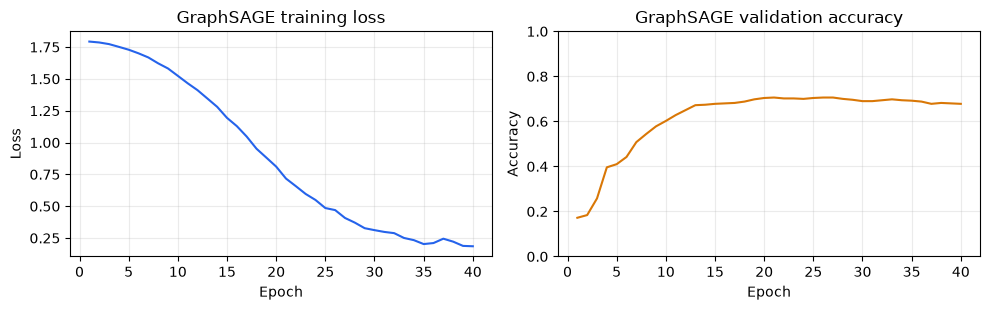

In [4]:
seed_everything()


def build_adjacency(edge_index, num_nodes):
    neighbors = [[] for _ in range(num_nodes)]
    for src, dst in edge_index.t().tolist():
        if src != dst:
            neighbors[src].append(dst)
    return neighbors


def sample_fanouts(target_nodes, fanouts, neighbors):
    """GraphSAGE mini-batch: from the targets downward, keep `fanout` neighbors per node.

    The frontier at the next layer is the current nodes plus the nodes just drawn,
    so a node's own vector is still available when the layer concatenates.
    """
    frontiers = [None] * (len(fanouts) + 1)
    frontiers[-1] = target_nodes.detach().cpu()
    neighbor_lists = [None] * len(fanouts)
    for layer in reversed(range(len(fanouts))):
        nodes = frontiers[layer + 1]
        fanout = fanouts[layer]
        chosen = torch.empty(nodes.numel(), fanout, dtype=torch.long)
        for row, node in enumerate(nodes.tolist()):
            pool = neighbors[node]
            if not pool:
                chosen[row] = node
            else:
                pick = torch.randint(len(pool), (fanout,))
                chosen[row] = torch.tensor([pool[int(i)] for i in pick.tolist()])
        neighbor_lists[layer] = chosen
        frontiers[layer] = torch.unique(torch.cat([nodes, chosen.reshape(-1)]))
    return frontiers, neighbor_lists


def neighbor_mean(h, edge_index):
    """Mean of every neighbor. Used at test time, when nothing is sampled."""
    num_nodes, width = h.size()
    out = torch.zeros(num_nodes, width, device=h.device, dtype=h.dtype)
    src, dst = edge_index
    out.index_add_(0, dst, h[src])
    deg = torch.zeros(num_nodes, device=h.device, dtype=h.dtype)
    deg.index_add_(0, dst, torch.ones(dst.numel(), device=h.device, dtype=h.dtype))
    mean = out / deg.clamp_min(1).unsqueeze(1)
    mean[deg == 0] = h[deg == 0]
    return mean


class GraphSAGE(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout):
        super().__init__()
        # The concatenation [own vector || neighbor mean] doubles the input width.
        self.lin1 = nn.Linear(in_channels * 2, hidden_channels)
        self.lin2 = nn.Linear(hidden_channels * 2, out_channels)
        self.dropout = dropout

    def _step(self, h, nodes, neighbor_index, linear, activate):
        own = h[nodes]
        neigh = h[neighbor_index].mean(dim=1)
        out = linear(torch.cat([own, neigh], dim=-1))
        if activate:
            out = F.dropout(F.relu(out), p=self.dropout, training=self.training)
        return out

    def sampled_forward(self, x, frontiers, neighbor_lists):
        h = x
        for layer, linear in enumerate((self.lin1, self.lin2)):
            nodes = frontiers[layer + 1]
            out = self._step(h, nodes, neighbor_lists[layer], linear, activate=layer == 0)
            updated = h.new_zeros(x.size(0), out.size(1))
            updated[nodes] = out
            h = updated
        return h[frontiers[-1]]

    def full_forward(self, x, edge_index):
        h = x
        for layer, linear in enumerate((self.lin1, self.lin2)):
            neigh = neighbor_mean(h, edge_index)
            out = linear(torch.cat([h, neigh], dim=-1))
            if layer == 0:
                out = F.dropout(F.relu(out), p=self.dropout, training=self.training)
            h = out
        return h


adjacency = build_adjacency(data.edge_index, data.num_nodes)
x_all = data.x.to(DEVICE)
y_all = data.y.to(DEVICE)
full_edges = data.edge_index.to(DEVICE)
train_idx = data.train_mask.nonzero(as_tuple=False).view(-1)

model = GraphSAGE(dataset.num_node_features, HIDDEN, dataset.num_classes, DROPOUT).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def train_epoch():
    model.train()
    order = train_idx[torch.randperm(train_idx.numel())]
    total_loss = 0.0
    total_nodes = 0
    for start in range(0, order.numel(), BATCH_SIZE):
        batch = order[start : start + BATCH_SIZE]
        frontiers, neighbor_lists = sample_fanouts(batch, FANOUTS, adjacency)
        frontiers = [nodes.to(DEVICE) for nodes in frontiers]
        neighbor_lists = [neigh.to(DEVICE) for neigh in neighbor_lists]
        optimizer.zero_grad()
        logits = model.sampled_forward(x_all, frontiers, neighbor_lists)
        loss = F.cross_entropy(logits, y_all[batch.to(DEVICE)])
        loss.backward()
        optimizer.step()
        total_loss += float(loss.item()) * batch.numel()
        total_nodes += batch.numel()
    return total_loss / total_nodes


@torch.no_grad()
def predict():
    model.eval()
    return model.full_forward(x_all, full_edges).argmax(dim=-1).cpu()


fit("GraphSAGE", model, train_epoch, predict)


# FastGCN


Epoch 01 | loss 1.794 | validation 17.6%


Epoch 10 | loss 1.766 | validation 26.6%


Epoch 20 | loss 1.724 | validation 58.0%


Epoch 30 | loss 1.613 | validation 44.2%


Epoch 40 | loss 1.525 | validation 70.4%
FastGCN | best epoch 38 | train 90.0% | val 72.8% | test 72.5%


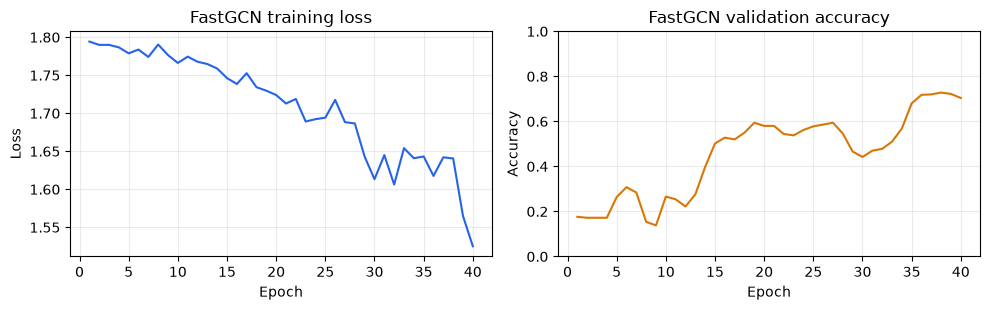

In [5]:
seed_everything()


def symmetric_adjacency(edge_index, num_nodes):
    """Dense D^{-1/2} (A + I) D^{-1/2}, the usual GCN neighborhood matrix."""
    edge_index, _ = add_self_loops(edge_index, num_nodes=num_nodes)
    ones = torch.ones(edge_index.size(1))
    adj = torch.sparse_coo_tensor(edge_index, ones, (num_nodes, num_nodes)).coalesce()
    row, col = adj.indices()
    deg = torch.sparse.sum(adj, dim=1).to_dense().clamp_min(1)
    scale = deg.pow(-0.5)
    dense = torch.zeros(num_nodes, num_nodes)
    dense[row, col] = adj.values() * scale[row] * scale[col]
    return dense


def column_norm_distribution(kernel):
    """q(v) proportional to the squared column norm of A_hat."""
    scores = kernel.pow(2).sum(dim=0)
    return scores / scores.sum()


class FastGCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout):
        super().__init__()
        self.lin1 = nn.Linear(in_channels, hidden_channels)
        self.lin2 = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout

    def aggregate(self, h_source, source_ids, target_ids, kernel, q):
        # (1 / t) * sum_j kernel[u, v_j] / q(v_j) * h(v_j) estimates (kernel @ h)[u].
        block = kernel[target_ids][:, source_ids]
        weights = block / q[source_ids].clamp_min(1e-12)
        return (weights @ h_source) / source_ids.shape[0]

    def encode(self, ax):
        # ax = A_hat @ X is precomputed. This layer is exact.
        hidden = self.lin1(ax)
        return F.dropout(F.relu(hidden), p=self.dropout, training=self.training)

    def sampled_forward(self, ax, kernel, q, batch_ids, num_samples):
        hidden = self.encode(ax)
        chosen = torch.multinomial(q, num_samples, replacement=True)
        return self.lin2(self.aggregate(hidden[chosen], chosen, batch_ids, kernel, q))

    def full_forward(self, x, kernel):
        hidden = self.encode(kernel @ x)
        return self.lin2(kernel @ hidden)


kernel = symmetric_adjacency(data.edge_index, data.num_nodes).to(DEVICE)
q = column_norm_distribution(kernel).to(DEVICE)
x_all = data.x.to(DEVICE)
y_all = data.y.to(DEVICE)
# Input features never change, so this product is computed once.
ax_all = kernel @ x_all
train_idx = data.train_mask.nonzero(as_tuple=False).view(-1)

model = FastGCN(dataset.num_node_features, HIDDEN, dataset.num_classes, DROPOUT).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def train_epoch():
    model.train()
    order = train_idx[torch.randperm(train_idx.numel())]
    losses = []
    for start in range(0, order.numel(), BATCH_SIZE):
        batch_ids = order[start : start + BATCH_SIZE].to(DEVICE)
        optimizer.zero_grad()
        logits = model.sampled_forward(ax_all, kernel, q, batch_ids, FASTGCN_SAMPLES)
        loss = F.cross_entropy(logits, y_all[batch_ids])
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return float(sum(losses) / len(losses))


@torch.no_grad()
def predict():
    model.eval()
    return model.full_forward(x_all, kernel).argmax(dim=-1).cpu()


fit("FastGCN", model, train_epoch, predict)


# ASGCN


Epoch 01 | loss 1.795 | validation 26.0%


Epoch 10 | loss 1.741 | validation 31.2%


Epoch 20 | loss 1.693 | validation 66.8%


Epoch 30 | loss 1.569 | validation 65.2%


Epoch 40 | loss 1.472 | validation 69.0%


ASGCN | best epoch 38 | train 92.5% | val 70.4% | test 71.1%


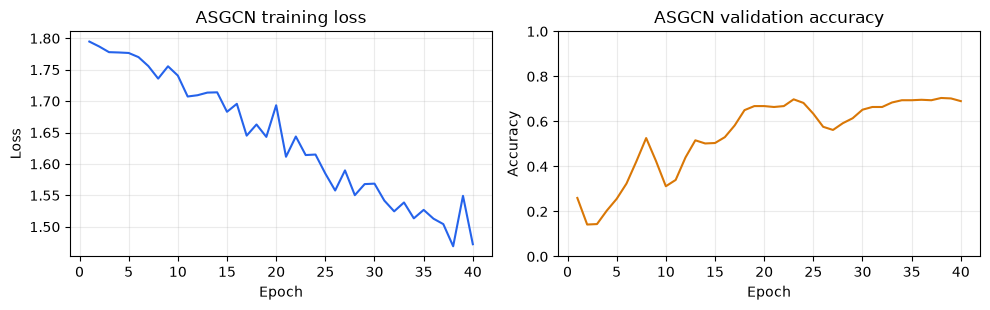

In [6]:
seed_everything()


def transition_matrix(edge_index, num_nodes):
    """Row-normalized A + I. Row u is the neighbor distribution p(v | u)."""
    edge_index, _ = add_self_loops(edge_index, num_nodes=num_nodes)
    ones = torch.ones(edge_index.size(1))
    adj = torch.sparse_coo_tensor(edge_index, ones, (num_nodes, num_nodes)).coalesce()
    row, col = adj.indices()
    deg = torch.sparse.sum(adj, dim=1).to_dense().clamp_min(1)
    dense = torch.zeros(num_nodes, num_nodes)
    dense[row, col] = adj.values() / deg[row]
    return dense


class ASGCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout):
        super().__init__()
        self.lin1 = nn.Linear(in_channels, hidden_channels)
        self.lin2 = nn.Linear(hidden_channels, out_channels)
        self.skip = nn.Linear(in_channels, hidden_channels)
        self.dropout = dropout

    def sample_layer(self, parent_ids, transition, num_samples):
        # q(v | parents) grows when v is a likely neighbor of the parent set.
        scores = transition[parent_ids].pow(2).sum(dim=0)
        q = scores / scores.sum().clamp_min(1e-12)
        chosen = torch.multinomial(q, num_samples, replacement=True)
        return chosen, q

    def aggregate(self, h_source, source_ids, target_ids, transition, q):
        block = transition[target_ids][:, source_ids]
        weights = block / q[source_ids].clamp_min(1e-12)
        return (weights @ h_source) / source_ids.shape[0]

    def sampled_forward(self, x, transition, batch_ids, sample_sizes):
        input_size, hidden_size = sample_sizes
        # Top-down. The hidden sample depends on the batch, then the input sample depends on that.
        hidden_ids, q_hidden = self.sample_layer(batch_ids, transition, hidden_size)
        input_ids, q_input = self.sample_layer(hidden_ids, transition, input_size)
        hidden = self.aggregate(x[input_ids], input_ids, hidden_ids, transition, q_input)
        hidden = F.relu(self.lin1(hidden))
        hidden = F.dropout(hidden, p=self.dropout, training=self.training)
        near = self.aggregate(hidden, hidden_ids, batch_ids, transition, q_hidden)
        # The skip reuses the input sample, so we do not draw a second pool of nodes.
        far = self.skip(self.aggregate(x[input_ids], input_ids, batch_ids, transition, q_input))
        return self.lin2(near + far)

    def full_forward(self, x, transition):
        hidden = F.relu(self.lin1(transition @ x))
        hidden = F.dropout(hidden, p=self.dropout, training=self.training)
        near = transition @ hidden
        far = self.skip(transition @ x)
        return self.lin2(near + far)


transition = transition_matrix(data.edge_index, data.num_nodes).to(DEVICE)
x_all = data.x.to(DEVICE)
y_all = data.y.to(DEVICE)
train_idx = data.train_mask.nonzero(as_tuple=False).view(-1)

model = ASGCN(dataset.num_node_features, HIDDEN, dataset.num_classes, DROPOUT).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def train_epoch():
    model.train()
    order = train_idx[torch.randperm(train_idx.numel())]
    losses = []
    for start in range(0, order.numel(), BATCH_SIZE):
        batch_ids = order[start : start + BATCH_SIZE].to(DEVICE)
        optimizer.zero_grad()
        logits = model.sampled_forward(x_all, transition, batch_ids, LAYER_SAMPLES)
        loss = F.cross_entropy(logits, y_all[batch_ids])
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return float(sum(losses) / len(losses))


@torch.no_grad()
def predict():
    model.eval()
    return model.full_forward(x_all, transition).argmax(dim=-1).cpu()


fit("ASGCN", model, train_epoch, predict)


# GraphSAINT


Estimating how often random walks visit each node and edge...


Epoch 01 | loss 1.789 | validation 19.2%


Epoch 10 | loss 1.147 | validation 28.4%


Epoch 20 | loss 0.373 | validation 58.2%


Epoch 30 | loss 0.295 | validation 64.0%


Epoch 40 | loss 0.283 | validation 67.4%
GraphSAINT | best epoch 38 | train 100.0% | val 70.6% | test 69.4%


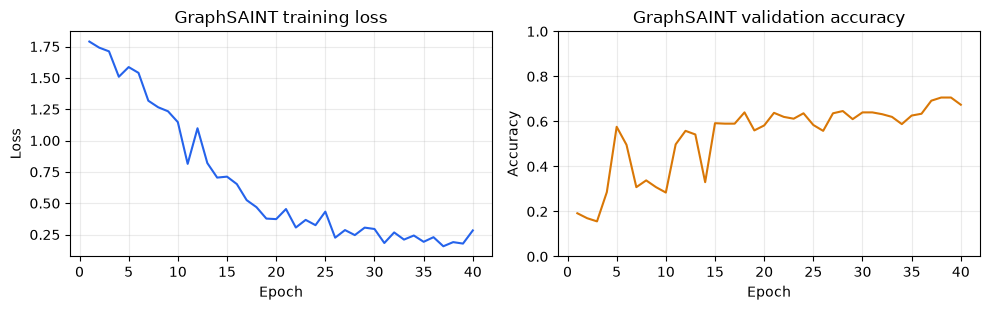

In [7]:
seed_everything()


def build_adjacency(edge_index, num_nodes):
    neighbors = [[] for _ in range(num_nodes)]
    for src, dst in edge_index.t().tolist():
        if src != dst:
            neighbors[src].append(dst)
    return neighbors


def random_walk_nodes(neighbors, num_starts, walk_length, num_nodes):
    """Nodes visited by `num_starts` walks. The subgraph is everything they touch."""
    current = torch.randint(0, num_nodes, (num_starts,)).tolist()
    visited = set(current)
    for _ in range(walk_length):
        nxt = []
        for node in current:
            pool = neighbors[node]
            step = node if not pool else pool[int(torch.randint(len(pool), ()))]
            nxt.append(step)
            visited.add(step)
        current = nxt
    return torch.tensor(sorted(visited), dtype=torch.long)


def induced_edges(node_ids, edge_index, num_nodes):
    """Edges with both ends inside `node_ids`, relabeled to 0..len(node_ids)-1."""
    inside = torch.zeros(num_nodes, dtype=torch.bool)
    inside[node_ids] = True
    src, dst = edge_index
    keep = inside[src] & inside[dst]
    new_id = torch.full((num_nodes,), -1, dtype=torch.long)
    new_id[node_ids] = torch.arange(node_ids.numel())
    sub_edges = torch.stack([new_id[src[keep]], new_id[dst[keep]]], dim=0)
    return sub_edges, keep


class WalkBatch:
    def __init__(self, x, y, edge_index, edge_weight, edge_norm, node_norm, train_mask):
        self.x = x
        self.y = y
        self.edge_index = edge_index
        self.edge_weight = edge_weight
        self.edge_norm = edge_norm
        self.node_norm = node_norm
        self.train_mask = train_mask
        self.num_nodes = int(x.size(0))
        self.num_edges = int(edge_index.size(1))


class GraphConvScratch(nn.Module):
    """Weighted sum of neighbor vectors, plus a separate linear map of the node itself."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.neighbor = nn.Linear(in_channels, out_channels, bias=False)
        self.root = nn.Linear(in_channels, out_channels)

    def forward(self, x, edge_index, edge_weight):
        src, dst = edge_index
        messages = self.neighbor(x)
        out = torch.zeros(x.size(0), messages.size(1), device=x.device, dtype=messages.dtype)
        if src.numel():
            out.index_add_(0, dst, messages[src] * edge_weight.unsqueeze(1))
        return out + self.root(x)


class GraphSAINTNet(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout):
        super().__init__()
        self.conv1 = GraphConvScratch(in_channels, hidden_channels)
        self.conv2 = GraphConvScratch(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index, edge_weight):
        x = self.conv1(x, edge_index, edge_weight)
        x = F.dropout(F.relu(x), p=self.dropout, training=self.training)
        return self.conv2(x, edge_index, edge_weight)


saint_neighbors = build_adjacency(data.edge_index, data.num_nodes)
src, dst = data.edge_index
in_degree = torch.zeros(data.num_nodes)
in_degree.index_add_(0, dst, torch.ones(dst.numel()))
# A neighbor shared by many nodes is down-weighted. Sampling corrections sit on top of this.
base_edge_weight = in_degree.clamp_min(1).reciprocal()[dst]


def estimate_sampling_norms():
    """Count how often walks visit each node and edge. That estimates p_v and p_uv."""
    node_count = torch.zeros(data.num_nodes)
    edge_count = torch.zeros(data.edge_index.size(1))
    seen = 0
    n_subgraphs = 0
    target = data.num_nodes * SAMPLE_COVERAGE
    while seen < target:
        nodes = random_walk_nodes(saint_neighbors, BATCH_SIZE, WALK_LENGTH, data.num_nodes)
        _, keep = induced_edges(nodes, data.edge_index, data.num_nodes)
        node_count[nodes] += 1
        edge_count[keep] += 1
        seen += int(nodes.numel())
        n_subgraphs += 1
    node_norm = n_subgraphs / node_count.clamp_min(0.1) / data.num_nodes
    edge_norm = node_count[src] / edge_count.clamp_min(1e-6)
    edge_norm = edge_norm.clamp(max=1e4)
    edge_norm[edge_count == 0] = 0.1
    return node_norm, edge_norm


print("Estimating how often random walks visit each node and edge...")
node_norm, edge_norm = estimate_sampling_norms()


def make_walk_batch():
    nodes = random_walk_nodes(saint_neighbors, BATCH_SIZE, WALK_LENGTH, data.num_nodes)
    sub_edges, keep = induced_edges(nodes, data.edge_index, data.num_nodes)
    return WalkBatch(
        x=data.x[nodes],
        y=data.y[nodes],
        edge_index=sub_edges,
        edge_weight=base_edge_weight[keep],
        edge_norm=edge_norm[keep],
        node_norm=node_norm[nodes],
        train_mask=data.train_mask[nodes],
    )


model = GraphSAINTNet(dataset.num_node_features, HIDDEN, dataset.num_classes, DROPOUT).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def train_epoch():
    model.train()
    losses = []
    for _ in range(SAINT_STEPS):
        sampled = make_walk_batch()
        if not bool(sampled.train_mask.any()):
            continue
        optimizer.zero_grad()
        weight = (sampled.edge_norm * sampled.edge_weight).to(DEVICE)
        logits = model(sampled.x.to(DEVICE), sampled.edge_index.to(DEVICE), weight)
        labeled = sampled.train_mask
        # node_norm is larger for nodes the walks rarely visit.
        weights = sampled.node_norm[labeled].to(DEVICE)
        per_node = F.cross_entropy(logits, sampled.y.to(DEVICE), reduction="none")[labeled.to(DEVICE)]
        loss = (per_node * weights).sum() / weights.sum().clamp_min(1e-12)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.item()))
    if not losses:
        raise RuntimeError("No training labels were sampled. Increase BATCH_SIZE or SAINT_STEPS.")
    return float(sum(losses) / len(losses))


@torch.no_grad()
def predict():
    model.eval()
    logits = model(data.x.to(DEVICE), data.edge_index.to(DEVICE), base_edge_weight.to(DEVICE))
    return logits.argmax(dim=-1).cpu()


fit("GraphSAINT", model, train_epoch, predict)


# ClusterGCN


Partitioning Citeseer into 8 clusters...
Cluster sizes: [347, 719, 331, 325, 519, 328, 327, 431]


Epoch 01 | loss 1.794 | validation 21.4%


Epoch 10 | loss 1.504 | validation 55.8%


Epoch 20 | loss 0.820 | validation 69.8%


Epoch 30 | loss 0.555 | validation 72.2%


Epoch 40 | loss 0.383 | validation 70.8%
ClusterGCN | best epoch 30 | train 98.3% | val 72.2% | test 71.1%


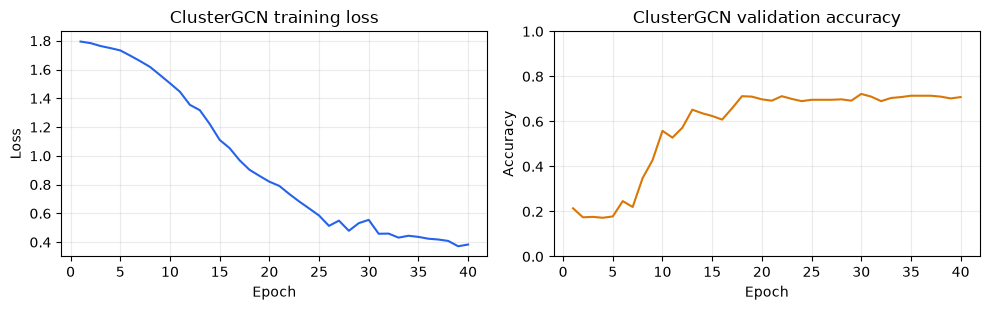

In [8]:
seed_everything()


def partition_nodes(edge_index, num_nodes, num_clusters, seed):
    """Grow same-sized clusters by walking out from seeds.

    The ClusterGCN paper uses METIS. On Cora and Citeseer a walk is enough,
    and it does not leave almost every node in a single cluster.
    """
    neighbors = [[] for _ in range(num_nodes)]
    for src, dst in edge_index.t().tolist():
        if src != dst:
            neighbors[src].append(dst)

    rng = np.random.default_rng(seed)
    for nodes in neighbors:
        rng.shuffle(nodes)

    labels = np.full(num_nodes, -1, dtype=np.int64)
    unlabeled = set(range(num_nodes))
    target = int(np.ceil(num_nodes / num_clusters))

    def grow(start, cluster, limit):
        queue = [start]
        labels[start] = cluster
        unlabeled.remove(start)
        filled = 1
        head = 0
        while head < len(queue) and filled < limit:
            current = queue[head]
            head += 1
            for nxt in neighbors[current]:
                if labels[nxt] != -1:
                    continue
                labels[nxt] = cluster
                unlabeled.remove(nxt)
                queue.append(nxt)
                filled += 1
                if filled >= limit:
                    break

    for cluster in range(num_clusters):
        if not unlabeled:
            break
        start = int(rng.choice(np.array(list(unlabeled))))
        grow(start, cluster, target)

    # Nodes a full cluster could not reach join the smallest neighboring cluster.
    while unlabeled:
        start = unlabeled.pop()
        nearby = [labels[node] for node in neighbors[start] if labels[node] >= 0]
        if nearby:
            counts = {cluster: nearby.count(cluster) for cluster in set(nearby)}
            chosen = max(counts, key=counts.get)
        else:
            sizes = np.bincount(labels[labels >= 0], minlength=num_clusters)
            chosen = int(np.argmin(sizes))
        labels[start] = chosen

    return torch.from_numpy(labels).long()


def gcn_aggregate(x, edge_index):
    """Multiply by D^{-1/2} (A + I) D^{-1/2}. Self-loops are added here."""
    num_nodes = x.size(0)
    loops = torch.arange(num_nodes, device=x.device)
    row = torch.cat([edge_index[0], loops])
    col = torch.cat([edge_index[1], loops])
    deg = torch.zeros(num_nodes, device=x.device, dtype=x.dtype)
    deg.index_add_(0, row, torch.ones(row.numel(), device=x.device, dtype=x.dtype))
    scale = deg.clamp_min(1).pow(-0.5)
    weight = scale[row] * scale[col]
    out = torch.zeros_like(x)
    out.index_add_(0, row, x[col] * weight.unsqueeze(1))
    return out


class ClusterGCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout):
        super().__init__()
        self.lin1 = nn.Linear(in_channels, hidden_channels)
        self.lin2 = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.lin1(gcn_aggregate(x, edge_index))
        x = F.dropout(F.relu(x), p=self.dropout, training=self.training)
        return self.lin2(gcn_aggregate(x, edge_index))


print(f"Partitioning {DATASET_NAME} into {NUM_CLUSTERS} clusters...")
cluster_id = partition_nodes(data.edge_index, data.num_nodes, NUM_CLUSTERS, SEED)
print("Cluster sizes:", torch.bincount(cluster_id).tolist())

model = ClusterGCN(dataset.num_node_features, HIDDEN, dataset.num_classes, DROPOUT).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def train_epoch():
    model.train()
    order = torch.randperm(NUM_CLUSTERS)
    losses = []
    for start in range(0, NUM_CLUSTERS, CLUSTERS_PER_BATCH):
        chosen = order[start : start + CLUSTERS_PER_BATCH]
        node_ids = torch.isin(cluster_id, chosen).nonzero(as_tuple=False).view(-1)
        # The induced subgraph keeps edges that run between the chosen clusters.
        sub_edges, _ = subgraph(
            node_ids, data.edge_index, relabel_nodes=True, num_nodes=data.num_nodes
        )
        mask = data.train_mask[node_ids].to(DEVICE)
        if not bool(mask.any()):
            continue
        optimizer.zero_grad()
        logits = model(data.x[node_ids].to(DEVICE), sub_edges.to(DEVICE))
        loss = F.cross_entropy(logits[mask], data.y[node_ids].to(DEVICE)[mask])
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    if not losses:
        raise RuntimeError("No cluster batch contained a training node.")
    return float(sum(losses) / len(losses))


@torch.no_grad()
def predict():
    model.eval()
    logits = model(data.x.to(DEVICE), data.edge_index.to(DEVICE))
    return logits.argmax(dim=-1).cpu()


fit("ClusterGCN", model, train_epoch, predict)


# Comparison

In [9]:
order = ["GraphSAGE", "FastGCN", "ASGCN", "GraphSAINT", "ClusterGCN"]
print(f"{'Model':<14}{'Train':>10}{'Val':>10}{'Test':>10}")
for name in order:
    scores = results[name]
    print(f"{name:<14}{scores['train']:>10.1%}{scores['val']:>10.1%}{scores['test']:>10.1%}")


Model              Train       Val      Test
GraphSAGE          99.2%     70.6%     68.8%
FastGCN            90.0%     72.8%     72.5%
ASGCN              92.5%     70.4%     71.1%
GraphSAINT        100.0%     70.6%     69.4%
ClusterGCN         98.3%     72.2%     71.1%
